In [26]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from src.graphs import load_instances, find_instance, json_to_graph
from src.hamiltonians import max_cut_hamiltonian, bisection_hamiltonian, generate_penalty_A
from src.qaoa import build_qaoa, hamiltonian_diagonal, energy, energy_landscape, optimize_qaoa, warm_start

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
instances = load_instances("../data/instances.json")

betas = np.linspace(0, np.pi / 2, 50)
gammas = np.linspace(0, np.pi, 50)

In [28]:
# desenez harta pentru p = 1; marchez minimul pe desen
def plot_landscape(energies, betas, gammas, title, path):
    image = plt.imshow(
        energies,
        origin="lower",
        extent=[gammas[0], gammas[-1], betas[0], betas[-1]],
        aspect="auto",
    )
    i, j = np.unravel_index(np.argmin(energies), energies.shape)
    plt.scatter(gammas[j], betas[i], color="red", marker="x")

    plt.colorbar(image, label="Energy <H>")
    plt.xlabel("gamma (cost angle)")
    plt.ylabel("beta (mixer angle)")
    plt.title(title)
    plt.savefig(path, dpi=150)
    plt.show()

    print("minimum energy:", energies[i, j], "at beta =", betas[i], "gamma =", gammas[j])

In [70]:
instance = find_instance(instances, "ring_12")
graph = json_to_graph(instance)
print(instance["name"], "| nodes:", graph.number_of_nodes(), "| edges:", graph.number_of_edges())

ring_12 | nodes: 12 | edges: 12


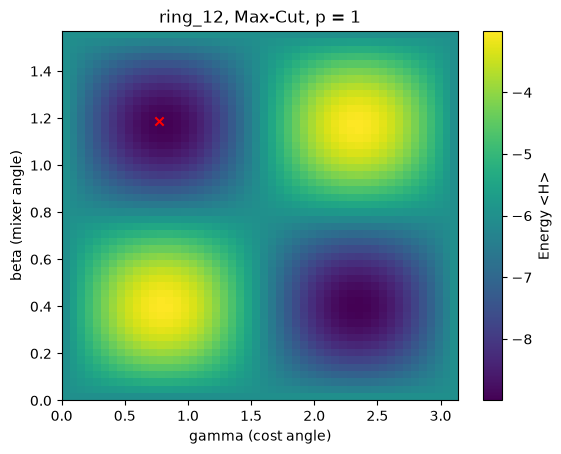

minimum energy: -8.996918089125478 at beta = 1.1861115120696157 gamma = 0.7693696294505615


In [ ]:
H = max_cut_hamiltonian(graph)
circuit = build_qaoa(H, 1)
diagonal = hamiltonian_diagonal(H)

energies = energy_landscape(circuit, diagonal, betas, gammas)
plot_landscape(energies, betas, gammas, instance["name"] + ", Max-Cut, p = 1", "../figures/S_landscape_" + instance["name"] + "_maxcut.png")

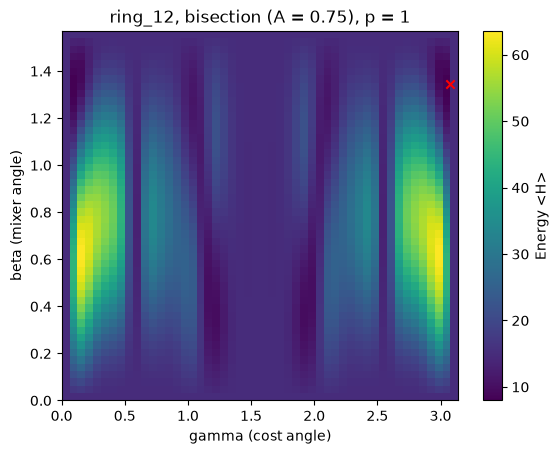

minimum energy: 7.953582397615064 at beta = 1.3463968515384828 gamma = 3.077478517802246


In [ ]:
A = generate_penalty_A(graph)
H = bisection_hamiltonian(graph, A)
circuit = build_qaoa(H, 1)
diagonal = hamiltonian_diagonal(H)

energies = energy_landscape(circuit, diagonal, betas, gammas)
plot_landscape(energies, betas, gammas, instance["name"] + ", bisection (A = " + str(A) + "), p = 1", "../figures/S_landscape_" + instance["name"] + "_bisection.png")

In [35]:
instance = find_instance(instances, "random_12")
graph = json_to_graph(instance)
print(instance["name"], "| nodes:", graph.number_of_nodes(), "| edges:", graph.number_of_edges())

random_12 | nodes: 12 | edges: 30


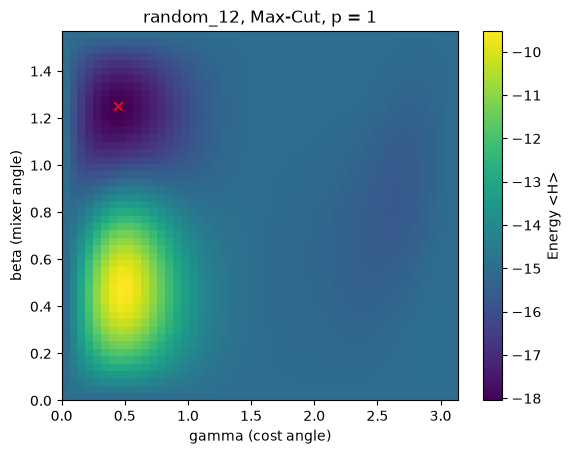

minimum energy: -18.050568459930368 at beta = 1.2502256478571625 gamma = 0.4487989505128276


In [ ]:
H = max_cut_hamiltonian(graph)
circuit = build_qaoa(H, 1)
diagonal = hamiltonian_diagonal(H)

energies = energy_landscape(circuit, diagonal, betas, gammas)
plot_landscape(energies, betas, gammas, instance["name"] + ", Max-Cut, p = 1", "../figures/S_landscape_" + instance["name"] + "_maxcut.png")

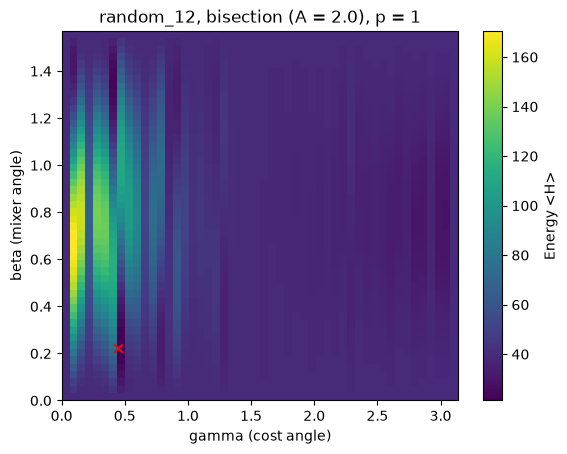

minimum energy: 21.277115248177886 at beta = 0.2243994752564138 gamma = 0.4487989505128276


In [ ]:
A = generate_penalty_A(graph)
H = bisection_hamiltonian(graph, A)
circuit = build_qaoa(H, 1)
diagonal = hamiltonian_diagonal(H)

energies = energy_landscape(circuit, diagonal, betas, gammas)
plot_landscape(energies, betas, gammas, instance["name"] + ", bisection (A = " + str(A) + "), p = 1", "../figures/S_landscape_" + instance["name"] + "_bisection.png")

In [38]:
rows_warm = []

for instance in instances:
    graph = json_to_graph(instance)

    for problem in ["maxcut", "bisection"]:
        if problem == "maxcut":
            H = max_cut_hamiltonian(graph)
        else:
            H = bisection_hamiltonian(graph, generate_penalty_A(graph))

        previous_params = None

        for p in [1, 2, 3]:
            if previous_params is None:
                best_energy, best_params = optimize_qaoa(H, p)
            else:
                best_energy, best_params = optimize_qaoa(H, p, initial_params=warm_start(previous_params))

            previous_params = best_params

            row = {
                "name": instance["name"],
                "graph_type": instance["graph_type"],
                "n": instance["n"],
                "problem": problem,
                "p": p,
                "energy": best_energy,
                "params": list(best_params),
                # TODO: the metrics from the next bullet
            }
            rows_warm.append(row)

    print(instance["name"], "done")

ring_6 done
grid_6 done
regular3_6 done
random_6 done
complete_6 done
ring_8 done
grid_8 done
regular3_8 done
random_8 done
complete_8 done
ring_10 done
grid_10 done
regular3_10 done
random_10 done
complete_10 done
ring_12 done
grid_12 done
regular3_12 done
random_12 done
complete_12 done
ring_14 done
grid_14 done
regular3_14 done
random_14 done
complete_14 done


In [39]:
import json
import pandas as pd

with open("../results/params_warm.json", "w") as f:
    json.dump(rows_warm, f, indent=2)

pd.DataFrame(rows_warm).to_csv("../results/sim_ideal_warm.csv", index=False)

In [41]:
sim = pd.DataFrame(rows_warm)

violations = []
for (name, problem), group in sim.groupby(["name", "problem"]):
    energies = group.sort_values("p")["energy"].tolist()
    if energies[1] > energies[0] + 1e-6 or energies[2] > energies[1] + 1e-6:
        violations.append((name, problem, energies))

print(len(violations), "cases where energy increases with p")
for v in violations:
    print(v)

0 cases where energy increases with p


### Diagnostic: warm start on grid_12, bisection
Check that the p = 3 warm start (p = 2 angles + one layer with angles 0)
has exactly the energy found at p = 2. If it does, a later energy increase
can only come from the optimization code, not from the warm start itself.

In [ ]:
import json
with open("../results/params_warm.json") as f:
    rows_warm = json.load(f)

instance = find_instance(instances, "grid_12")
graph = json_to_graph(instance)
H = bisection_hamiltonian(graph, generate_penalty_A(graph))
diagonal = hamiltonian_diagonal(H)

sim = pd.DataFrame(rows_warm)
row_p2 = sim[(sim["name"] == "grid_12") & (sim["problem"] == "bisection") & (sim["p"] == 2)].iloc[0]

circuit_p3 = build_qaoa(H, 3)
start = warm_start(row_p2["params"])

print("energy found at p = 2:        ", row_p2["energy"])
print("energy of the p = 3 warm start:", energy(start, circuit_p3, diagonal))

energy found at p = 2:         11.597638172974477
energy of the p = 3 warm start: 11.597638172974477


### Diagnostic: COBYLA started from the warm start
Run COBYLA directly from the warm start. If the final energy is lower than
the start energy, the optimizer works correctly from this point, so any
monotonicity violation must come from how `optimize_qaoa` handles its starts.
Result: 11.598 → 11.564 (improves; stops at the 200-evaluation limit).

In [43]:
from scipy.optimize import minimize

res = minimize(energy, start, args=(circuit_p3, diagonal), method="COBYLA", options={"maxiter": 200})

print("start energy:   ", energy(start, circuit_p3, diagonal))
print("final energy:   ", res.fun)
print("function calls: ", res.nfev)
print("message:        ", res.message)

start energy:    11.597638172974477
final energy:    11.56385090016401
function calls:  200
message:         Return from COBYLA because the objective function has been evaluated MAXFUN times.


### Diagnostic: `optimize_qaoa` with the warm start
The full function must return an energy at least as low as COBYLA started
from the warm start alone (11.564). Before the fix it returned a higher value:
the optimization loop overwrote each start with a new random one, so the warm
start was never used. After the fix both values match.

In [44]:
best_energy, best_params = optimize_qaoa(H, 3, initial_params=start)
print(best_energy)

11.56385090016401


### Reload the optimized angles
Load the saved angles instead of rerunning the optimization (~30 min),
so the metrics below can be computed after a kernel restart.

In [46]:
import json

with open("../results/params_warm.json") as f:
    rows_warm = json.load(f)

print(len(rows_warm), "rows loaded")

150 rows loaded


### Test: `qaoa_metrics` on a hand-computed example
Graph with one edge (0–1), bisection, probabilities [0.1, 0.4, 0.3, 0.2]
for bitstrings 00, 01, 10, 11. Only 01 and 10 are balanced, and both cut
the edge, so by hand: valid_fraction = 0.4 + 0.3 = 0.7, mean_cut = 1,
p_optimal = 0.7, best_sample_cut = 1. The function must return exactly these values.

In [48]:
import networkx as nx
from src.qaoa import qaoa_metrics

two = nx.Graph([(0, 1)])
probabilities = np.array([0.1, 0.4, 0.3, 0.2])

print(qaoa_metrics(two, "bisection", probabilities, ["01", "10"]))

{'valid_fraction': 0.7, 'mean_cut': 1.0, 'p_optimal': 0.7, 'best_sample_cut': 1.0}


In [49]:
from qiskit.quantum_info import Statevector
from src.classical import max_cut_bruteforce, bisection_bruteforce

for row in rows_warm:
    instance = find_instance(instances, row["name"])
    graph = json_to_graph(instance)

    if row["problem"] == "maxcut":
        H = max_cut_hamiltonian(graph)
        optimum, optimal_bitstrings = max_cut_bruteforce(graph)
    else:
        H = bisection_hamiltonian(graph, generate_penalty_A(graph))
        optimum, optimal_bitstrings = bisection_bruteforce(graph)

    circuit = build_qaoa(H, row["p"])
    probabilities = Statevector(circuit.assign_parameters(row["params"])).probabilities()

    metrics = qaoa_metrics(graph, row["problem"], probabilities, optimal_bitstrings)

    row["optimum"] = optimum
    row.update(metrics)

    print(row["name"], row["problem"], "p =", row["p"], "done")

ring_6 maxcut p = 1 done
ring_6 maxcut p = 2 done
ring_6 maxcut p = 3 done
ring_6 bisection p = 1 done
ring_6 bisection p = 2 done
ring_6 bisection p = 3 done
grid_6 maxcut p = 1 done
grid_6 maxcut p = 2 done
grid_6 maxcut p = 3 done
grid_6 bisection p = 1 done
grid_6 bisection p = 2 done
grid_6 bisection p = 3 done
regular3_6 maxcut p = 1 done
regular3_6 maxcut p = 2 done
regular3_6 maxcut p = 3 done
regular3_6 bisection p = 1 done
regular3_6 bisection p = 2 done
regular3_6 bisection p = 3 done
random_6 maxcut p = 1 done
random_6 maxcut p = 2 done
random_6 maxcut p = 3 done
random_6 bisection p = 1 done
random_6 bisection p = 2 done
random_6 bisection p = 3 done
complete_6 maxcut p = 1 done
complete_6 maxcut p = 2 done
complete_6 maxcut p = 3 done
complete_6 bisection p = 1 done
complete_6 bisection p = 2 done
complete_6 bisection p = 3 done
ring_8 maxcut p = 1 done
ring_8 maxcut p = 2 done
ring_8 maxcut p = 3 done
ring_8 bisection p = 1 done
ring_8 bisection p = 2 done
ring_8 bisecti

In [50]:
assert len(rows_warm) > 0, "nothing to save"

with open("../results/params_warm.json", "w") as f:
    json.dump(rows_warm, f, indent=2)

sim = pd.DataFrame(rows_warm)
sim.to_csv("../results/sim_ideal_warm.csv", index=False)
sim.head()

,name,graph_type,n,problem,p,energy,params,optimum,valid_fraction,mean_cut,p_optimal,best_sample_cut
0,ring_6,ring,6,maxcut,1,-4.500000,"[4.319651696097815, 0.7854179748494212]",6,1.000000,4.500000,0.285170,6.0
1,ring_6,ring,6,maxcut,2,-5.000000,"[2.1922079915273467, 1.8987006654129979, 2.485...",6,1.000000,5.000000,0.536337,6.0
2,ring_6,ring,6,maxcut,3,-5.999978,"[0.9291108949907011, 1.1319301304631444, 0.638...",6,1.000000,5.999978,0.999989,6.0
3,ring_6,ring,6,bisection,1,3.983389,"[2.0469323996434663, 1.2932211268582325]",2,0.632956,2.268502,0.575329,2.0
4,ring_6,ring,6,bisection,2,3.047887,"[2.0437789146196876, 1.3618344466547236, 1.288...",2,0.898472,2.301063,0.804954,2.0


In [51]:
maxcut = sim[sim["problem"] == "maxcut"]
difference = (maxcut["mean_cut"] + maxcut["energy"]).abs().max()
print("largest |mean_cut + energy| on Max-Cut:", difference)

largest |mean_cut + energy| on Max-Cut: 7.531752999057062e-13


In [58]:
def transfer_test(sim, source_name, target_name, problem, p):
    """Apply the best angles of source_name to target_name, without any optimization,
    and compare with the angles optimized directly for target_name."""
    source_row = sim[(sim["name"] == source_name) & (sim["problem"] == problem) & (sim["p"] == p)].iloc[0]
    target_row = sim[(sim["name"] == target_name) & (sim["problem"] == problem) & (sim["p"] == p)].iloc[0]

    # 1. the target problem: Hamiltonian and optimal solutions
    graph = json_to_graph(find_instance(instances, target_name))
    if problem == "maxcut":
        H = max_cut_hamiltonian(graph)
        optimum, optimal_bitstrings = max_cut_bruteforce(graph)
    else:
        H = bisection_hamiltonian(graph, generate_penalty_A(graph))
        optimum, optimal_bitstrings = bisection_bruteforce(graph)

    # 2. the target circuit, with the SOURCE angles
    circuit = build_qaoa(H, p)
    probabilities = Statevector(circuit.assign_parameters(source_row["params"])).probabilities()
    transferred = qaoa_metrics(graph, problem, probabilities, optimal_bitstrings)

    # 3. quality between 0 and 1 for both problems (1 = optimal)
    if problem == "maxcut":
        direct_ratio = target_row["mean_cut"] / optimum
        transferred_ratio = transferred["mean_cut"] / optimum
    else:
        direct_ratio = optimum / target_row["mean_cut"]
        transferred_ratio = optimum / transferred["mean_cut"]

    return {
        "source": source_name,
        "target": target_name,
        "problem": problem,
        "p": p,
        "direct_ratio": direct_ratio,
        "transferred_ratio": transferred_ratio,
        "kept": transferred_ratio / direct_ratio,
        "direct_p_optimal": target_row["p_optimal"],
        "transferred_p_optimal": transferred["p_optimal"],
        "direct_valid_fraction": target_row["valid_fraction"],
        "transferred_valid_fraction": transferred["valid_fraction"],
    }

In [59]:
transfer_rows = []

for source_name, target_name in [("ring_8", "ring_12"), ("random_8", "random_12")]:
    for problem in ["maxcut", "bisection"]:
        for p in [1, 2, 3]:
            transfer_rows.append(transfer_test(sim, source_name, target_name, problem, p))

transfer = pd.DataFrame(transfer_rows)
transfer.to_csv("../results/transfer.csv", index=False)
transfer

,source,target,problem,p,direct_ratio,transferred_ratio,kept,direct_p_optimal,transferred_p_optimal,direct_valid_fraction,transferred_valid_fraction
0,ring_8,ring_12,maxcut,1,0.750000,0.750000,1.000000,0.040473,0.040474,1.000000,1.000000
1,ring_8,ring_12,maxcut,2,0.833333,0.833333,1.000000,0.152678,0.152678,1.000000,1.000000
2,ring_8,ring_12,maxcut,3,0.874995,0.874997,1.000003,0.293016,0.292964,1.000000,1.000000
3,ring_8,ring_12,bisection,1,0.316171,0.318024,1.005859,0.010462,0.011938,0.581444,0.617417
4,ring_8,ring_12,bisection,2,0.318897,0.512781,1.607981,0.019999,0.132155,0.936595,0.335613
5,ring_8,ring_12,bisection,3,0.319612,0.501854,1.570197,0.020247,0.208734,0.930364,0.579235
6,random_8,random_12,maxcut,1,0.785134,0.780922,0.994635,0.021277,0.024584,1.000000,1.000000
7,random_8,random_12,maxcut,2,0.855307,0.827722,0.967748,0.089475,0.090079,1.000000,1.000000
8,random_8,random_12,maxcut,3,0.896807,0.877074,0.977997,0.180204,0.165464,1.000000,1.000000
9,random_8,random_12,bisection,1,0.625036,0.658436,1.053437,0.000471,0.014221,0.383773,0.202462


In [ ]:
# de aici incepe partea cu graficul -----------------------------------------

reference = pd.read_csv("../data/reference.csv")[["name", "problem", "random_mean"]]

sim = pd.DataFrame(rows_warm)
sim = sim.merge(reference, on=["name", "problem"])

sim["score"] = (sim["random_mean"] - sim["mean_cut"]) / (sim["random_mean"] - sim["optimum"])

sim[["name", "problem", "p", "mean_cut", "optimum", "random_mean", "score"]].head(10)

,name,problem,p,mean_cut,optimum,random_mean,score
0,ring_6,maxcut,1,4.500000,6,3.0,0.500000
1,ring_6,maxcut,2,5.000000,6,3.0,0.666667
2,ring_6,maxcut,3,5.999978,6,3.0,0.999993
3,ring_6,bisection,1,2.268502,2,3.6,0.832186
4,ring_6,bisection,2,2.301063,2,3.6,0.811835
5,ring_6,bisection,3,2.393185,2,3.6,0.754259
6,grid_6,maxcut,1,5.050979,7,3.5,0.443137
7,grid_6,maxcut,2,5.996679,7,3.5,0.713337
8,grid_6,maxcut,3,6.743662,7,3.5,0.926761
9,grid_6,bisection,1,3.740561,3,4.2,0.382866


In [61]:
plot_data = sim[sim["graph_type"] != "complete"]

summary = plot_data.groupby(["problem", "graph_type", "p"])["score"].agg(["mean", "std"]).reset_index()
summary

,problem,graph_type,p,mean,std
0,bisection,grid,1,0.303106,1.221269e-01
1,bisection,grid,2,0.318278,2.891824e-01
2,bisection,grid,3,0.335897,2.589994e-01
3,bisection,random,1,0.158530,2.657223e-01
4,bisection,random,2,0.187393,2.898348e-01
5,bisection,random,3,0.257766,1.946774e-01
6,bisection,regular3,1,0.411861,2.327419e-01
7,bisection,regular3,2,0.496322,3.014711e-01
8,bisection,regular3,3,0.477390,3.326606e-01
9,bisection,ring,1,0.211950,3.470175e-01


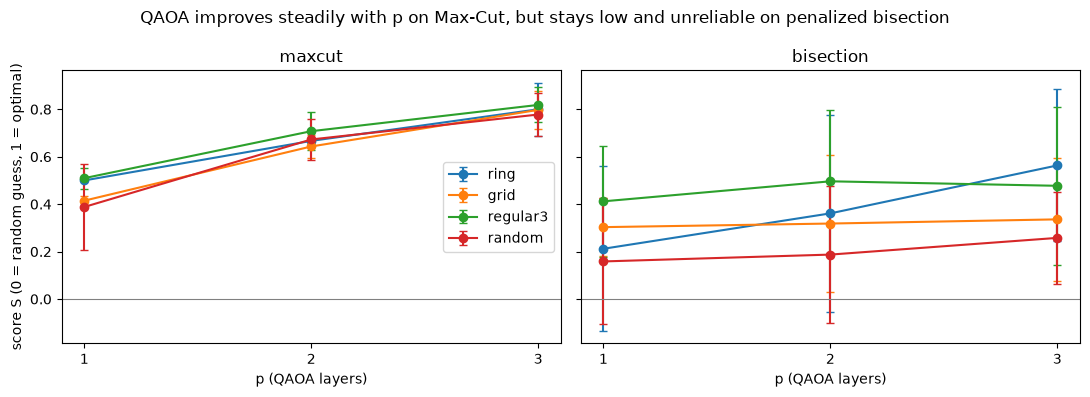

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, problem in zip(axes, ["maxcut", "bisection"]):
    part = summary[summary["problem"] == problem]
    for graph_type in ["ring", "grid", "regular3", "random"]:
        g = part[part["graph_type"] == graph_type]
        ax.errorbar(g["p"], g["mean"], yerr=g["std"], marker="o", capsize=3, label=graph_type)

    ax.set_title(problem)
    ax.set_xlabel("p (QAOA layers)")
    ax.set_xticks([1, 2, 3])
    ax.axhline(0, color="gray", linewidth=0.8)

axes[0].set_ylabel("score S (0 = random guess, 1 = optimal)")
axes[0].legend()
fig.suptitle("QAOA improves steadily with p on Max-Cut, but stays low and unreliable on penalized bisection")

plt.tight_layout()
plt.savefig("../figures/S_quality_vs_p.png", dpi=150)
plt.show()

In [64]:
sim.to_csv("../results/sim_ideal_warm.csv", index=False)